In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
df = pd.read_csv('Expanded_data_with_more_features.csv')



In [2]:

df.head()




,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75


In [3]:
df.tail()

,Unnamed: 0,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
30636,816,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
30637,890,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
30638,911,female,NaN,high school,free/reduced,completed,married,sometimes,no,1.0,private,5 - 10,61,70,67
30639,934,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93
30640,960,male,group B,some college,standard,none,married,never,no,1.0,school_bus,5 - 10,64,60,58


In [11]:

df.dtypes


Gender                      str
EthnicGroup                 str
ParentEduc                  str
LunchType                   str
TestPrep                    str
ParentMaritalStatus         str
PracticeSport               str
IsFirstChild                str
NrSiblings                int32
TransportMeans              str
WklyStudyHours              str
MathScore                 int64
ReadingScore              int64
WritingScore              int64
Gender_Encoded            int64
WklyStudyHours_Encoded    int64
dtype: object

In [13]:

df.describe()


,NrSiblings,MathScore,ReadingScore,WritingScore,Gender_Encoded,WklyStudyHours_Encoded
count,30640.000000,30640.000000,30640.000000,30640.000000,30640.000000,30640.000000
mean,2.138446,66.558975,69.377709,68.418962,0.496638,1.900946
std,1.420715,15.361539,14.759161,15.443662,0.499997,0.654837
min,0.000000,0.000000,10.000000,4.000000,0.000000,1.000000
25%,1.000000,56.000000,59.000000,58.000000,0.000000,1.000000
50%,2.000000,67.000000,70.000000,69.000000,0.000000,2.000000
75%,3.000000,78.000000,80.000000,79.000000,1.000000,2.000000
max,7.000000,100.000000,100.000000,100.000000,1.000000,3.000000


In [14]:

df.isnull().sum()

duplicate_count = df.duplicated().sum()
print(duplicate_count)

# Set visual theme
sns.set_theme(style='whitegrid')


0


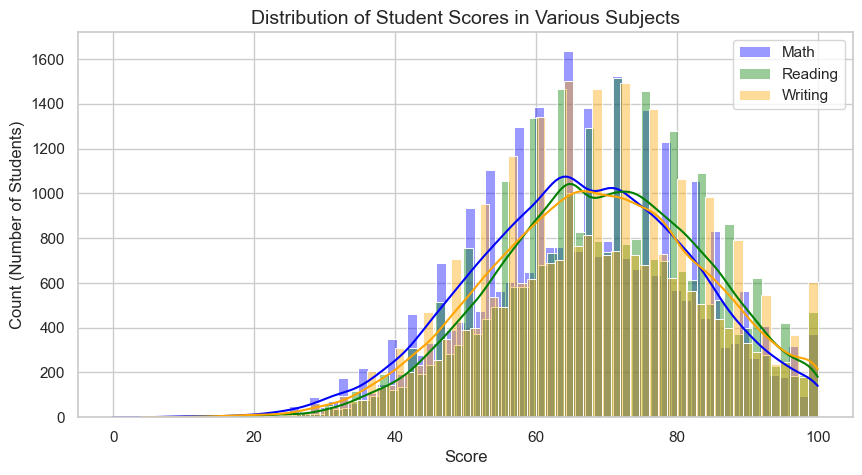

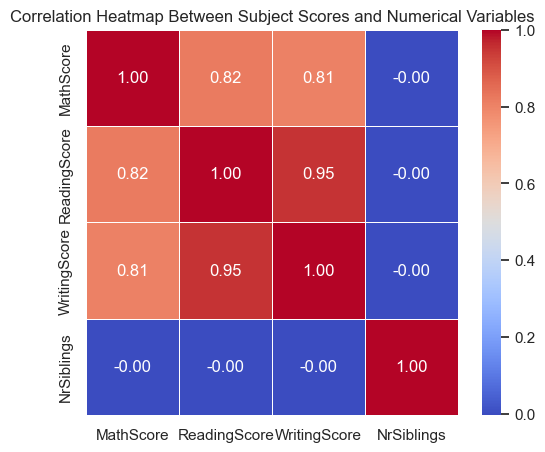

In [5]:

# -------------------------------------------------------------
# 1. Histogram & KDE: Distribution of Student Scores in Various Subjects
# -------------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.histplot(
    df['MathScore'], color='blue', label='Math', kde=True, alpha=0.4
)
sns.histplot(
    df['ReadingScore'],
    color='green',
    label='Reading',
    kde=True,
    alpha=0.4,
)
sns.histplot(
    df['WritingScore'],
    color='orange',
    label='Writing',
    kde=True,
    alpha=0.4,
)
plt.title('Distribution of Student Scores in Various Subjects', fontsize=14)
plt.xlabel('Score', fontsize=12)
plt.ylabel('Count (Number of Students)', fontsize=12)
plt.legend()
plt.show()

# -------------------------------------------------------------
# 2. Correlation Heatmap: Correlation Between Numerical Variables
# -------------------------------------------------------------
plt.figure(figsize=(6, 5))
numeric_cols = ['MathScore', 'ReadingScore', 'WritingScore', 'NrSiblings']
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
)
plt.title(
    'Correlation Heatmap Between Subject Scores and Numerical Variables',
    fontsize=12,
)
plt.show()


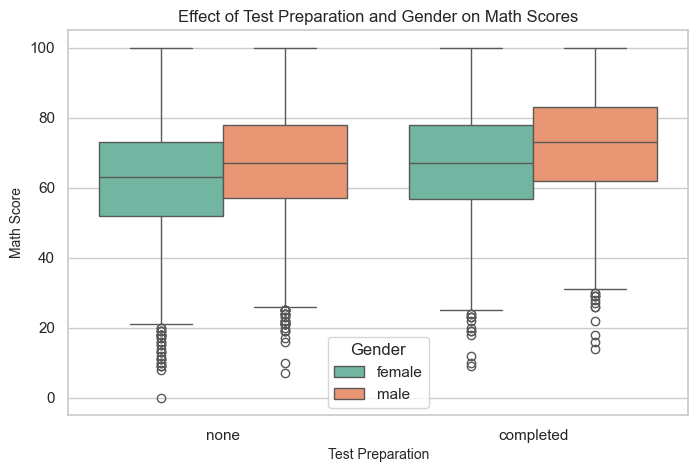

حجم الداتا سيت قبل المعالجة: (30641, 15)
إجمالي القيم المفقودة قبل المعالجة:
Unnamed: 0                0
Gender                    0
EthnicGroup            1840
ParentEduc             1845
LunchType                 0
TestPrep               1830
ParentMaritalStatus    1190
PracticeSport           631
IsFirstChild            904
NrSiblings             1572
TransportMeans         3134
WklyStudyHours          955
MathScore                 0
ReadingScore              0
WritingScore              0
dtype: int64



In [6]:

# -------------------------------------------------------------
# 3. Box Plot: Math Scores by Test Preparation and Gender
# -------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.boxplot(x='TestPrep', y='MathScore', hue='Gender', data=df, palette='Set2')
plt.title('Effect of Test Preparation and Gender on Math Scores', fontsize=12)
plt.xlabel('Test Preparation', fontsize=10)
plt.ylabel('Math Score', fontsize=10)
plt.legend(title='Gender')
plt.show()

print(f'حجم الداتا سيت قبل المعالجة: {df.shape}')
print(f'إجمالي القيم المفقودة قبل المعالجة:\n{df.isnull().sum()}\n')


In [7]:

# -------------------------------------------------------------
# 1. Handle Missing Values
# -------------------------------------------------------------
# ملء الأعمدة الرقمية بالوسيط (Median)
df['NrSiblings'] = df['NrSiblings'].fillna(df['NrSiblings'].median())

# ملء الأعمدة الفئوية بالقيمة الأكثر تكراراً (Mode)
cat_cols_with_nulls = [
    'EthnicGroup',
    'ParentEduc',
    'TestPrep',
    'ParentMaritalStatus',
    'PracticeSport',
    'IsFirstChild',
    'TransportMeans',
    'WklyStudyHours',
]
for col in cat_cols_with_nulls:
  df[col] = df[col].fillna(df[col].mode()[0])

print('--> 1. تم ملء جميع القيم المفقودة بنجاح.')

# -------------------------------------------------------------
# 2. Drop Redundant Columns
# -------------------------------------------------------------
# حذف عمود الفهرس الزائد 'Unnamed: 0' إن وجد
if 'Unnamed: 0' in df.columns:
  df = df.drop(columns=['Unnamed: 0'])

print('--> 2. تم حذف الأعمدة الزائدة (Redundant Columns).')

# -------------------------------------------------------------
# 3. Identify and Remove Duplicated Rows
# -------------------------------------------------------------
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates()
print(f'--> 3. عدد الصفوف المكررة التي تم إزالتها: {duplicates_before}')

# -------------------------------------------------------------
# 4. Additional Preprocessing (Data Types Correction)
# -------------------------------------------------------------
# تصحيح نوع البيانات لعمود عدد الإخوة ليصبح عدد صحيح (Integer)
df['NrSiblings'] = df['NrSiblings'].astype(int)
print(
    '--> 4. تم ضبط أنواع البيانات (Data Types) مثل تحويل NrSiblings إلى Integer.'
)

# -------------------------------------------------------------
# 5. Convert Categorical Columns into Numerical Columns (Encoding)
# -------------------------------------------------------------
# تحويل عمود الجنس (Gender) إلى أقيم رقمية (0 للإناث، 1 للذكور)
df['Gender_Encoded'] = df['Gender'].map({'female': 0, 'male': 1})

# تحويل ساعات الدراسة الأسبوعية إلى أرقام تعبيرية وترتيبية
study_mapping = {'< 5': 1, '5 - 10': 2, '> 10': 3}
df['WklyStudyHours_Encoded'] = df['WklyStudyHours'].map(study_mapping)

print('--> 5. تم تحويل الأعمدة الفئوية إلى رقمية (Encoding).')

print(f'\nحجم الداتا سيت النهائي بعد التنظيف والمعالجة: {df.shape}')
print(f'إجمالي القيم المفقودة الآن: {df.isnull().sum().sum()}')


--> 1. تم ملء جميع القيم المفقودة بنجاح.
--> 2. تم حذف الأعمدة الزائدة (Redundant Columns).
--> 3. عدد الصفوف المكررة التي تم إزالتها: 1
--> 4. تم ضبط أنواع البيانات (Data Types) مثل تحويل NrSiblings إلى Integer.
--> 5. تم تحويل الأعمدة الفئوية إلى رقمية (Encoding).

حجم الداتا سيت النهائي بعد التنظيف والمعالجة: (30640, 16)
إجمالي القيم المفقودة الآن: 0


In [8]:

#Data Selection and Manipulation
# اختيار أول 5 صفوف وأعمدة 'Gender' و 'MathScore' باستخدام الأسماء
loc_example = df.loc[0:4, ['Gender', 'MathScore']]
print('--- نتيجة استخدام loc[] ---')
print(loc_example)

# اختيار أول 5 صفوف وأول 3 أعمدة باستخدام المواقع الرقمية
iloc_example = df.iloc[0:5, 0:3]
print('--- نتيجة استخدام iloc[] ---')
print(iloc_example)

# إنشاء نسخة مصغرة بفهارس رقمية مخصصة لتوضيح الفرق
df_custom = df.head(5).copy()
df_custom.index = [10, 20, 30, 40, 50]

# استخدام loc (تشمل الفهرس 30)
print('--- استخدام loc (يشمل الحد الأخير) ---')
print(df_custom.loc[10:30, ['Gender', 'MathScore']])

# استخدام iloc (لا تشمل الموقع 2، تأخذ الموقع 0 و 1 فقط)
print('\n--- استخدام iloc (تعتمد على المواقع ولا تشمل الحد الأخير) ---')
print(df_custom.iloc[0:2, :2])

# تصفية الطالبات الإناث اللاتي تجاوزت درجاتهن في الرياضيات 85
filtered_df = df[(df['MathScore'] > 85) & (df['Gender'] == 'female')]
print(
    f'عدد الطلاب الذين يحققون الشرطين: {filtered_df.shape[0]} طالب وطالبة'
)
print(filtered_df[['Gender', 'MathScore', 'ReadingScore']].head())

# ترتيب الداتا سيت تنازلياً حسب أعلى درجات الرياضيات
sorted_df = df.sort_values(by='MathScore', ascending=False)
print('--- أعلى 5 طلاب في درجات الرياضيات ---')
print(
    sorted_df[['Gender', 'ParentEduc', 'MathScore', 'ReadingScore']].head()
)

# حساب متوسط درجات الرياضيات لكل جنس (ذكر / أنثى) للإجابة على السؤال التحليلي
groupby_result = df.groupby('Gender')['MathScore'].mean()
print('--- متوسط درجات الرياضيات حسب الجنس ---')
print(groupby_result)

# ضبط التصميم العام للرسوم
sns.set_theme(style='whitegrid')


--- نتيجة استخدام loc[] ---
   Gender  MathScore
0  female         71
1  female         69
2  female         87
3    male         45
4    male         76
--- نتيجة استخدام iloc[] ---
   Gender EthnicGroup          ParentEduc
0  female     group C   bachelor's degree
1  female     group C        some college
2  female     group B     master's degree
3    male     group A  associate's degree
4    male     group C        some college
--- استخدام loc (يشمل الحد الأخير) ---
    Gender  MathScore
10  female         71
20  female         69
30  female         87

--- استخدام iloc (تعتمد على المواقع ولا تشمل الحد الأخير) ---
    Gender EthnicGroup
10  female     group C
20  female     group C
عدد الطلاب الذين يحققون الشرطين: 1241 طالب وطالبة
     Gender  MathScore  ReadingScore
2    female         87            93
93   female         87            92
97   female         87           100
105  female         98            99
113  female         90            94
--- أعلى 5 طلاب في درجات الرياضيات

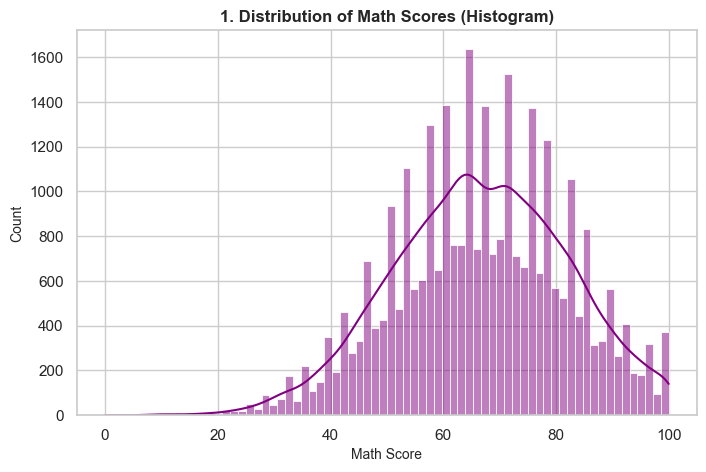

C:\Users\yosse\AppData\Local\Temp\ipykernel_26952\1095260918.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='EthnicGroup', y='ReadingScore', data=df, palette='Set3')


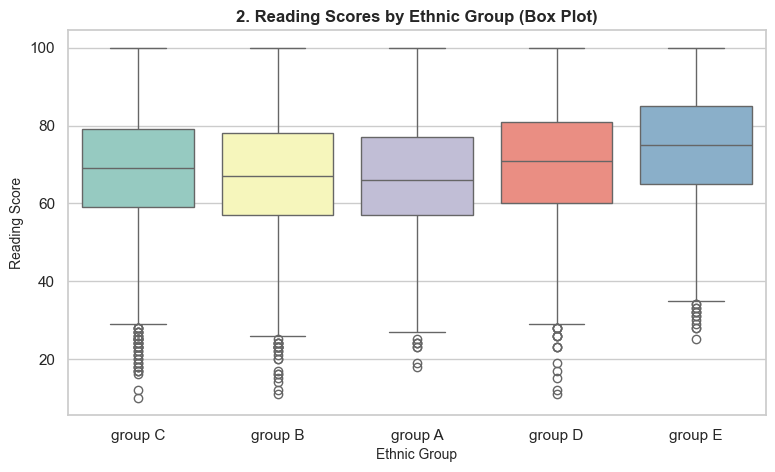

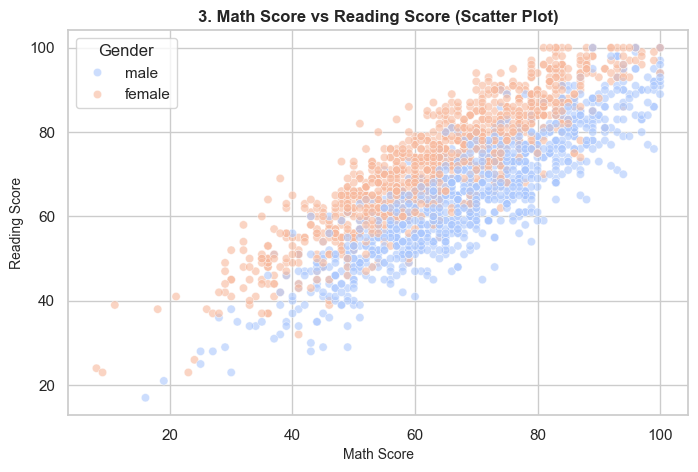

C:\Users\yosse\AppData\Local\Temp\ipykernel_26952\1095260918.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


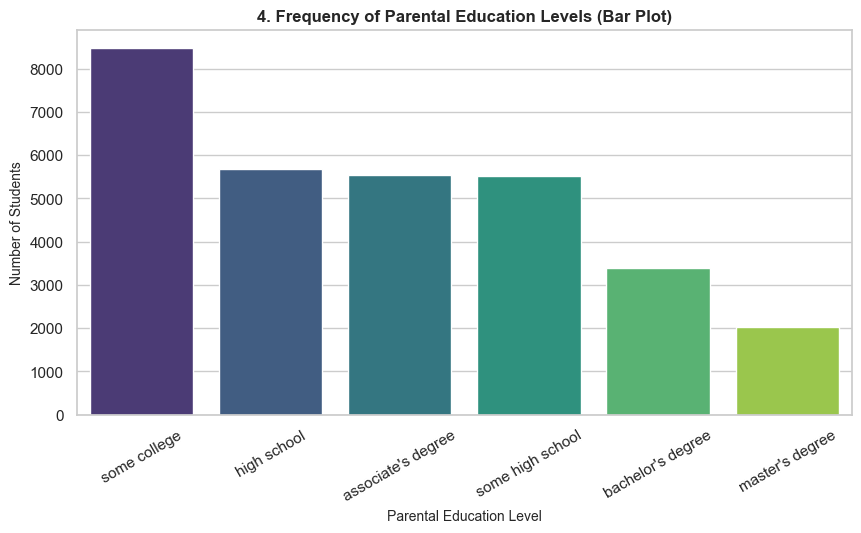

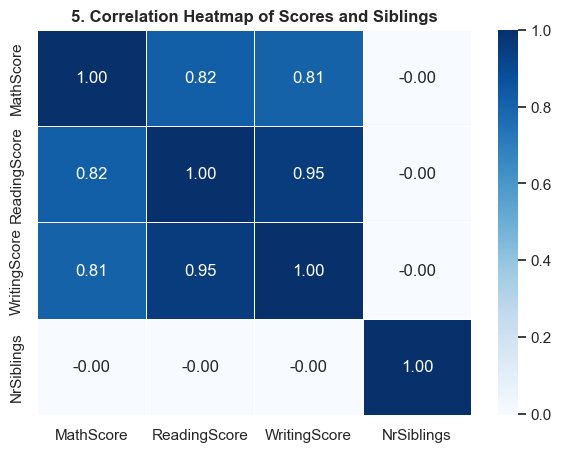

In [9]:

# -------------------------------------------------------------
# 1. Histogram (توزيع درجات الرياضيات)
# -------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.histplot(df['MathScore'], kde=True, color='purple')
plt.title(
    '1. Distribution of Math Scores (Histogram)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Math Score', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

# -------------------------------------------------------------
# 2. Box Plot (مقارنة درجات القراءة حسب المجموعات العرقية)
# -------------------------------------------------------------
plt.figure(figsize=(9, 5))
sns.boxplot(x='EthnicGroup', y='ReadingScore', data=df, palette='Set3')
plt.title(
    '2. Reading Scores by Ethnic Group (Box Plot)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Ethnic Group', fontsize=10)
plt.ylabel('Reading Score', fontsize=10)
plt.show()

# -------------------------------------------------------------
# 3. Scatter Plot (العلاقة بين درجات الرياضيات والقراءة)
# -------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='MathScore',
    y='ReadingScore',
    hue='Gender',
    data=df.sample(2000, random_state=42),
    alpha=0.6,
    palette='coolwarm',
)
plt.title(
    '3. Math Score vs Reading Score (Scatter Plot)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Math Score', fontsize=10)
plt.ylabel('Reading Score', fontsize=10)
plt.legend(title='Gender')
plt.show()

# -------------------------------------------------------------
# 4. Bar Plot / Count Plot (تكرار مستويات تعليم أولياء الأمور)
# -------------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.countplot(
    x='ParentEduc',
    data=df,
    order=df['ParentEduc'].value_counts().index,
    palette='viridis',
)
plt.title(
    '4. Frequency of Parental Education Levels (Bar Plot)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Parental Education Level', fontsize=10)
plt.ylabel('Number of Students', fontsize=10)
plt.xticks(rotation=30)
plt.show()

# -------------------------------------------------------------
# 5. Correlation Heatmap (خريطة الارتباط بين المتغيرات الرقمية)
# -------------------------------------------------------------
plt.figure(figsize=(7, 5))
numeric_cols = ['MathScore', 'ReadingScore', 'WritingScore', 'NrSiblings']
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5,
)
plt.title(
    '5. Correlation Heatmap of Scores and Siblings',
    fontsize=12,
    fontweight='bold',
)
plt.show()